# Visualización de Anotaciones WSI

Este notebook permite verificar visualmente que las anotaciones de QuPath (.geojson) se están leyendo y alineando correctamente con las imágenes (.tif).

In [1]:
import cv2
import numpy as np
import geojson
from shapely.geometry import shape, Polygon
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm

In [11]:


def visualize_annotations(img_rgb, annotations, alpha=0.25,only_class = False,class_to_see = '',overlay_bg = False):
    colors = {
        'Decidua': (255, 0, 0),
        'Labyrinth': (0, 255, 0),
        'Junctional Zone': (0, 0, 255),
        'no_labeled': (255, 255, 0),
        'background': (128, 128, 128)
    }
    
    overlay = img_rgb.copy()
    
    # Separar tissue de background
    if only_class:
        tissue_features = [f for f in annotations['features'] if f['properties'].get('name') == class_to_see]
    else:
        tissue_features = [f for f in annotations['features'] if f['properties'].get('name') != 'background']
    bg_features = [f for f in annotations['features'] if f['properties'].get('name') == 'background']
    
    # Dibujar tissue primero
    for feature in tissue_features:
        geom = shape(feature['geometry'])
        class_name = feature['properties'].get('name', 'unknown')
        color = colors.get(class_name, (128, 128, 128))
        print('color: ',color)
        if geom.geom_type == 'Polygon':
            polys = [geom]
        elif geom.geom_type == 'MultiPolygon':
            polys = list(geom.geoms)
        else:
            continue
        
        for poly in polys:
            ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
            cv2.fillPoly(overlay, [ext_coords], color)
            
            for interior in poly.interiors:
                int_coords = np.array(interior.coords, dtype=np.int32)
                cv2.fillPoly(overlay, [int_coords], (0, 0, 0))
    
    # Dibujar background en overlay separado con menor intensidad
    if overlay_bg:
        overlay_bg = img_rgb.copy()
        for feature in bg_features:
            geom = shape(feature['geometry'])
            
            if geom.geom_type == 'Polygon':
                polys = [geom]
            elif geom.geom_type == 'MultiPolygon':
                polys = list(geom.geoms)
            else:
                continue
            
            for poly in polys:
                ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
                cv2.fillPoly(overlay_bg, [ext_coords], (128, 128, 128))
                
                for interior in poly.interiors:
                    int_coords = np.array(interior.coords, dtype=np.int32)
                    cv2.fillPoly(overlay_bg, [int_coords], (0, 0, 0))
    
    result = cv2.addWeighted(img_rgb, 1 - alpha, overlay, alpha, 0)
    if overlay_bg:
        result = cv2.addWeighted(result, 1, overlay_bg, 0.15, 0)
    
    plt.figure(figsize=(15, 12))
    plt.imshow(result)
    plt.title('Anotaciones Superpuestas')
    plt.axis('off')
    
    legend_elements = [plt.Rectangle((0, 0), 1, 1, facecolor=np.array(c)/255) 
                       for c in colors.values()]
    plt.legend(legend_elements, colors.keys(), loc='upper right')
    plt.show()




color:  (255, 255, 0)


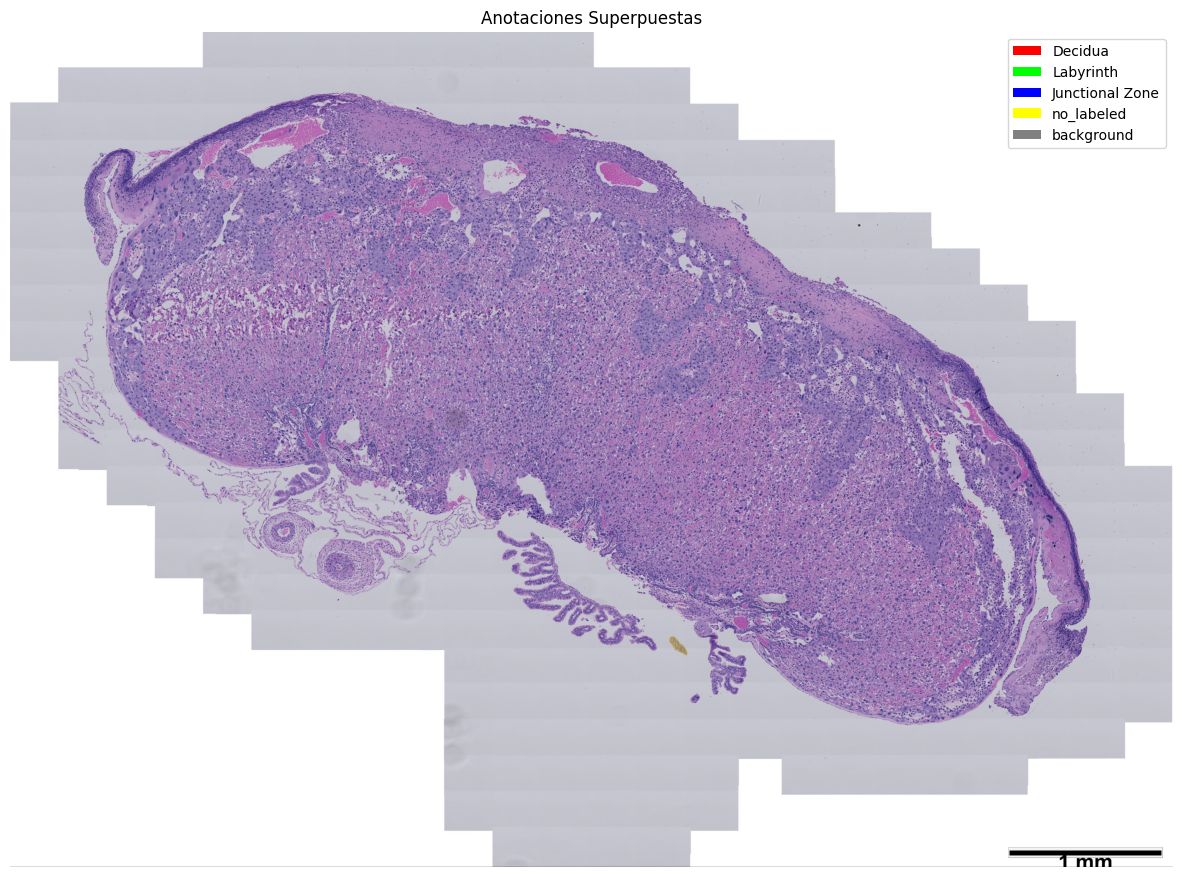

color:  (0, 0, 255)
color:  (0, 255, 0)
color:  (255, 0, 0)
color:  (0, 0, 255)
color:  (0, 255, 0)
color:  (255, 0, 0)


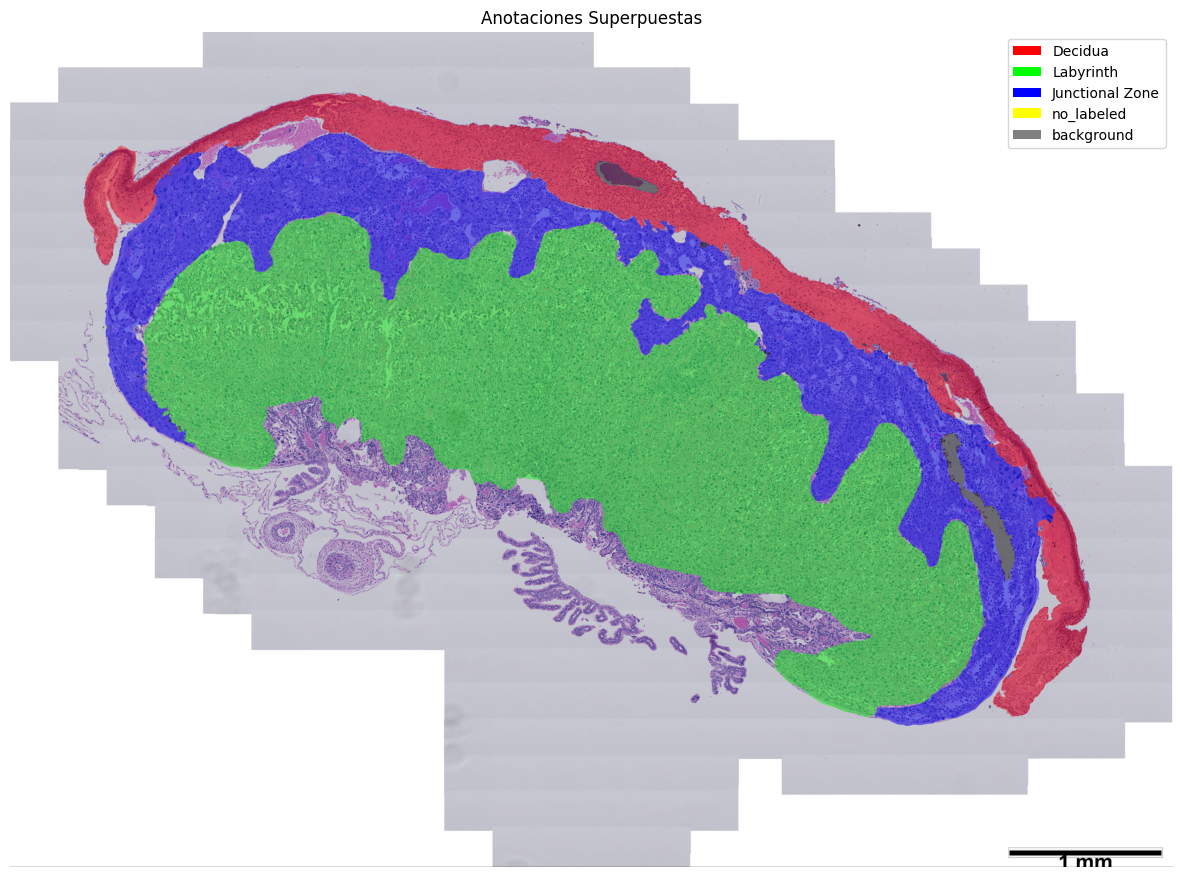

In [19]:

slide_id = 'slide_001'

img_path = '/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/raw/wsi_images/' + f"{slide_id}.tif"
img = cv2.imread(str(img_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

annot_path_raw = f"/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/raw/annotations_resized/{slide_id}.geojson"
annot_path = '/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/raw/annot_cleanned_test/slide_001.geojson'
with open(annot_path, 'r') as f:
    annotations = geojson.load(f)

with open(annot_path_raw, 'r') as f:
    annotations_raw = geojson.load(f)
visualize_annotations(img_rgb,annotations,alpha = 0.35,only_class=True,class_to_see='no_labeled')
visualize_annotations(img_rgb,annotations_raw,alpha = 0.45)

In [16]:
print(annotations[0])

{"geometry": {"coordinates": [[[[6260.0, 3647.0], [6259.0, 3648.0], [6252.0, 3648.0], [6251.0, 3649.0], [6249.0, 3649.0], [6248.0, 3650.0], [6246.0, 3650.0], [6245.0, 3651.0], [6244.0, 3651.0], [6243.0, 3652.0], [6241.0, 3652.0], [6240.0, 3653.0], [6238.0, 3653.0], [6237.0, 3654.0], [6236.0, 3654.0], [6235.0, 3655.0], [6233.0, 3655.0], [6232.0, 3656.0], [6231.0, 3656.0], [6230.0, 3657.0], [6229.0, 3657.0], [6228.0, 3658.0], [6227.0, 3658.0], [6225.0, 3660.0], [6224.0, 3660.0], [6221.0, 3663.0], [6220.0, 3663.0], [6218.0, 3665.0], [6217.0, 3665.0], [6216.0, 3666.0], [6215.0, 3666.0], [6212.0, 3669.0], [6211.0, 3669.0], [6208.0, 3672.0], [6208.0, 3673.0], [6206.0, 3675.0], [6205.0, 3675.0], [6204.0, 3676.0], [6204.0, 3677.0], [6203.0, 3678.0], [6202.0, 3678.0], [6202.0, 3679.0], [6197.0, 3684.0], [6197.0, 3685.0], [6194.0, 3688.0], [6194.0, 3689.0], [6193.0, 3690.0], [6193.0, 3691.0], [6192.0, 3692.0], [6192.0, 3693.0], [6191.0, 3694.0], [6191.0, 3695.0], [6189.0, 3697.0], [6189.0, 3699.

# Anotaciones reconstruidas post tiling

Encontrados 589 tiles para slide_052
Dimensiones reconstruidas: 8908x5612


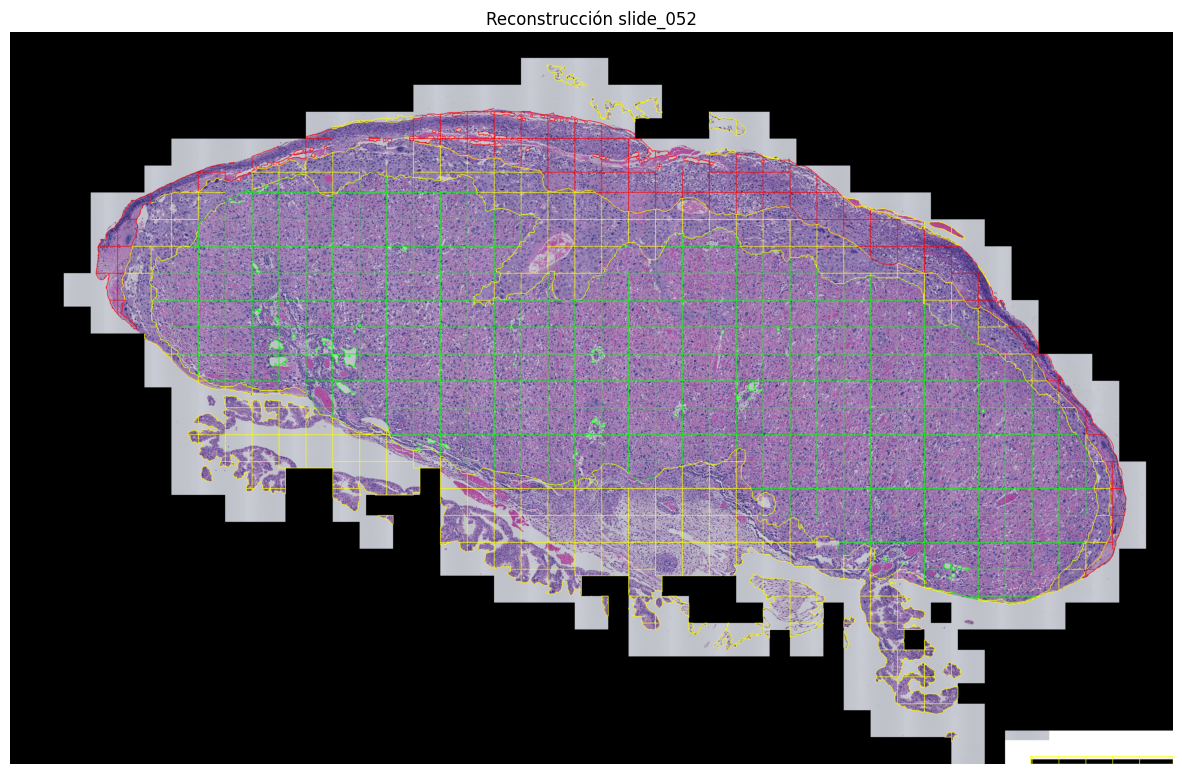

In [54]:
import cv2
import numpy as np
import os
import re
import glob

def get_tile_coords(filename):
    """Extrae coordenadas x, y del nombre del tile."""
    nums = re.findall(r'\d+', filename)
    if len(nums) >= 2:
        return int(nums[-2]), int(nums[-1])
    return 0, 0

def reconstruct_wsi_from_tiles(images_dir, labels_dir, slide_id, output_path=None,save = False, tile_size=1280):
    """Reconstruye una WSI a partir de sus tiles."""
    # Buscar tiles del slide
    pattern = os.path.join(images_dir, f"*{slide_id}*.jpg")
    image_files = sorted(glob.glob(pattern))
    
    if not image_files:
        print(f"No se encontraron tiles para {slide_id}")
        return None
    
    print(f"Encontrados {len(image_files)} tiles para {slide_id}")
    
    # Calcular tamaño total
    max_x, max_y = 0, 0
    for img_path in image_files:
        x, y = get_tile_coords(os.path.basename(img_path))
        if x > max_x: max_x = x
        if y > max_y: max_y = y
    
    total_w = max_x + tile_size
    total_h = max_y + tile_size
    print(f"Dimensiones reconstruidas: {total_w}x{total_h}")
    
    # Crear lienzo
    canvas = np.zeros((total_h, total_w, 3), dtype=np.uint8)
    
    # Colores para clases (BGR)
    class_colors = {
        0: (0, 0, 255),     # Decidua - Rojo
        1: (0, 255, 0),     # Labyrinth - Verde
        2: (255, 0, 0),     # Junctional Zone - Azul
        3: (0, 255, 255)    # background - Amarillo
    }
    
    # Procesar cada tile
    for img_path in image_files:
        filename = os.path.basename(img_path)
        x_offset, y_offset = get_tile_coords(filename)
        
        # Cargar imagen
        tile_img = cv2.imread(img_path)
        if tile_img is None:
            continue
        
        # Pegar en el canvas
        canvas[y_offset:y_offset+tile_size, x_offset:x_offset+tile_size] = tile_img
        
        # Cargar labels
        label_path = os.path.join(labels_dir, filename.replace('.jpg', '.txt'))
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                lines = f.readlines()
            
            for line in lines:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                
                cls = int(parts[0])
                coords = np.array(parts[1:], dtype=np.float32).reshape(-1, 2)
                
                # Convertir a coordenadas absolutas
                coords[:, 0] = coords[:, 0] * tile_size + x_offset
                coords[:, 1] = coords[:, 1] * tile_size + y_offset
                
                # Dibujar polígono
                color = class_colors.get(cls, (0, 255, 0))
                cv2.polylines(canvas, [coords.astype(np.int32)], True, color, thickness=3)
    
    # Guardar
    if output_path and save:
        cv2.imwrite(output_path, canvas)
        print(f"Reconstrucción guardada en: {output_path}")
    
    return canvas

# --- CONFIGURACIÓN ---
YOLO_DIR = "/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/processed/YOLO-256x256-50ovlp_V4_"
IMAGES_DIR = os.path.join(YOLO_DIR, "images/train")
LABELS_DIR = os.path.join(YOLO_DIR, "labels/train")

# Slide a reconstruir
SLIDE_ID = "slide_052"
OUTPUT_PATH = f"reconstruction_{SLIDE_ID}.jpg"

# Reconstruir
reconstructed = reconstruct_wsi_from_tiles(IMAGES_DIR, LABELS_DIR, SLIDE_ID, OUTPUT_PATH,tile_size=256)

# Mostrar resultado
if reconstructed is not None:
    import matplotlib.pyplot as plt
    # Reducir para visualización
    scale = 5000 / max(reconstructed.shape[1], reconstructed.shape[0])
    if scale < 1:
        display_h, display_w = int(reconstructed.shape[0] * scale), int(reconstructed.shape[1] * scale)
        display_img = cv2.resize(reconstructed, (display_w, display_h))
    else:
        display_img = reconstructed
    
    fig, ax = plt.subplots(figsize=(15, 10))
    ax.imshow(cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Reconstrucción {SLIDE_ID}")
    ax.axis("off")
    plt.show()

# VISUALIZACIÓN DATASET

# Test annotations

In [14]:
import cv2
import numpy as np
import geojson

#annot_path = "/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/raw/annotations_resized/slide_009.geojson"
annot_path = '/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/processed/ANNOT_CLEAN-V3_w_nolabeled/slide_009.geojson'

with open(annot_path, 'r') as f:
        annotations = geojson.load(f)


print(annotations.get('features'))


[{"geometry": {"coordinates": [[[7363.0, 1382.0], [7363.0, 1405.0], [7366.0, 1402.0], [7366.0, 1401.0], [7368.0, 1399.0], [7368.0, 1396.0], [7369.0, 1395.0], [7369.0, 1391.0], [7368.0, 1390.0], [7368.0, 1387.0], [7363.0, 1382.0]]], "type": "Polygon"}, "properties": {"class": "Decidua", "name": "Decidua"}, "type": "Feature"}, {"geometry": {"coordinates": [[[7369.0, 1369.0], [7369.0, 1371.0], [7370.0, 1372.0], [7370.0, 1374.0], [7373.0, 1377.0], [7373.0, 1379.0], [7374.0, 1380.0], [7374.0, 1382.0], [7375.0, 1382.0], [7376.0, 1383.0], [7376.0, 1385.0], [7377.0, 1385.0], [7378.0, 1386.0], [7378.0, 1388.0], [7379.0, 1388.0], [7380.0, 1389.0], [7380.0, 1386.0], [7379.0, 1385.0], [7379.0, 1379.0], [7377.0, 1377.0], [7377.0, 1375.0], [7372.0, 1370.0], [7372.0, 1369.0], [7369.0, 1369.0]]], "type": "Polygon"}, "properties": {"class": "Decidua", "name": "Decidua"}, "type": "Feature"}, {"geometry": {"coordinates": [[[5685.0, 623.0], [5684.0, 624.0], [5680.0, 624.0], [5679.0, 625.0], [5677.0, 625.0

In [8]:
features = annotations.get('features')

print(len(features[0]))

4


In [19]:
features[0].get('properties').get('name')

'Decidua'

In [13]:
features[0].get('geometry')

{"coordinates": [[[[6415.5, 649.25], [6412.75, 649.25], [6411.25, 649.25], [6410.0, 649.25], [6407.25, 652.0], [6405.0, 652.0], [6404.75, 652.25], [6402.75, 654.0], [6401.0, 654.0], [6400.75, 654.25], [6400.5, 654.25], [6398.5, 656.25], [6395.25, 656.25], [6393.25, 654.5], [6393.0, 654.25], [6392.75, 654.0], [6392.5, 654.0], [6388.5, 654.0], [6386.5, 652.0], [6384.25, 652.0], [6382.25, 650.0], [6382.0, 649.75], [6381.75, 649.75], [6377.75, 649.75], [6377.25, 649.25], [6366.1875, 649.25], [6366.09, 649.36], [6364.3325, 649.09], [6364.0, 649.0], [6363.0, 648.885], [6360.5, 648.5], [6359.6675, 648.5], [6357.5, 648.25], [6356.5, 648.25], [6354.75, 648.25], [6348.25, 649.0], [6341.75, 650.75], [6336.0, 654.0], [6332.2275, 657.205], [6326.665, 659.8675], [6324.0425, 660.4225], [6323.0, 660.5], [6314.0, 662.25], [6313.735, 662.335], [6307.25, 663.0], [6307.0825, 663.0325], [6304.25, 663.25], [6292.08, 665.6375], [6280.3825, 667.37], [6270.5, 668.0], [6269.485, 668.195], [6268.0, 668.25], [625

In [12]:
len(features[0].get('geometry').get('coordinates')[0])

24

In [17]:
count = 0
for i in annotations.get('features'):
    #print(i)
    if i.get('properties').get('name') == 'Decidua':
        count += 1

In [18]:
count

18